# 01_Station-level demand patterns and drivers
Builds an hourly station panel for the 229 study-area stations, then examines weekday vs. weekend flows, demand over time, station heterogeneity, and the effects of weather and holidays. The findings set the features and model choice for forecasting.

## 1. Load data

| Name | Source | Role |
|---|---|---|
| `trips_clean` | `data/processed/trips_*.parquet` | Cleaned trips, same rules as `00_data_ingest` |
| `study_stations` | `data/processed/study_stations.parquet` | 229 stations with capacity |
| `weather` | `data/external/weather_nyc_2025_06_09.csv` (Open-Meteo) | Hourly temperature and precipitation, Midtown Manhattan |

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

duckdb.sql("SET enable_progress_bar = false")
duckdb.sql("SET memory_limit = '4GB'")  # 8GB machine; leave room for the OS
external_dir = '../data/external'
processed_dir = '../data/processed'

start_date, end_date = '2025-06-01', '2025-10-01'
holidays = ['2025-06-19', '2025-07-04', '2025-09-01']  # Juneteenth, Independence Day, Labor Day

### Register the `trips_clean`, `study_stations` and `weather` views
`trips_clean` repeats the cleaning rules from `00_data_ingest`. The Open-Meteo CSV starts with three metadata lines and a header line, so the first four lines are skipped. Re-run this cell after a kernel restart.

In [2]:
duckdb.sql(f"""
CREATE OR REPLACE VIEW trips_clean AS
SELECT *
FROM '{processed_dir}/trips_*.parquet'
WHERE started_at >= '{start_date}'
  AND started_at <  '{end_date}'
  AND date_diff('second', started_at, ended_at) BETWEEN 60 AND 3 * 3600;

CREATE OR REPLACE VIEW study_stations AS
SELECT * FROM '{processed_dir}/study_stations.parquet';

CREATE OR REPLACE VIEW weather AS
SELECT *
FROM read_csv('{external_dir}/weather_nyc_2025_06_09.csv',
              skip = 4,
              header = false,
              columns = {{'ts': 'TIMESTAMP', 'temp_c': 'DOUBLE', 'precip_mm': 'DOUBLE'}});
""")

### Weather coverage
Expect 2,928 hourly rows (122 days) with no missing values.

In [3]:
duckdb.sql("""
SELECT COUNT(*)                                   AS n_hours,
       MIN(ts)                                    AS first_hour,
       MAX(ts)                                    AS last_hour,
       COUNT(*) FILTER (WHERE temp_c IS NULL)     AS null_temp,
       COUNT(*) FILTER (WHERE precip_mm IS NULL)  AS null_precip
FROM weather
""").show()

┌─────────┬─────────────────────┬─────────────────────┬───────────┬─────────────┐
│ n_hours │     first_hour      │      last_hour      │ null_temp │ null_precip │
│  int64  │      timestamp      │      timestamp      │   int64   │    int64    │
├─────────┼─────────────────────┼─────────────────────┼───────────┼─────────────┤
│    2928 │ 2025-06-01 00:00:00 │ 2025-09-30 23:00:00 │         0 │           0 │
└─────────┴─────────────────────┴─────────────────────┴───────────┴─────────────┘



## 2. Hourly station panel

### Build `station_hour`
One row per station per hour, including hours with no trips (zero-filled). `range()` generates every hour in the study period; departures and arrivals are joined onto that grid.

In [4]:
duckdb.sql(f"""
CREATE OR REPLACE TABLE station_hour AS
WITH hours AS (
    SELECT unnest(range(TIMESTAMP '{start_date}', TIMESTAMP '{end_date}', INTERVAL 1 HOUR)) AS hour_ts
),
dep AS (
    SELECT start_station_id AS station_id,
           date_trunc('hour', started_at) AS hour_ts,
           COUNT(*) AS departures
    FROM trips_clean
    WHERE start_station_id IN (SELECT station_id FROM study_stations)
    GROUP BY ALL
),
arr AS (
    -- trips ending after the study period are dropped so every hour is complete
    SELECT end_station_id AS station_id,
           date_trunc('hour', ended_at) AS hour_ts,
           COUNT(*) AS arrivals
    FROM trips_clean
    WHERE end_station_id IN (SELECT station_id FROM study_stations)
      AND ended_at < '{end_date}'
    GROUP BY ALL
)
SELECT s.station_id,
       h.hour_ts,
       COALESCE(d.departures, 0) AS departures,
       COALESCE(a.arrivals, 0)   AS arrivals
FROM study_stations s
CROSS JOIN hours h
LEFT JOIN dep d ON d.station_id = s.station_id AND d.hour_ts = h.hour_ts
LEFT JOIN arr a ON a.station_id = s.station_id AND a.hour_ts = h.hour_ts
""")

### Register the `panel` view
Adds calendar fields and weather. `day_type` is `holiday`, `weekend` or `weekday`; `dayofweek()` returns 0 for Sunday and 6 for Saturday.

In [5]:
holiday_list = ', '.join(f"DATE '{d}'" for d in holidays)

duckdb.sql(f"""
CREATE OR REPLACE VIEW panel AS
SELECT p.*,
       p.hour_ts::DATE      AS date,
       hour(p.hour_ts)      AS hr,
       dayofweek(p.hour_ts) AS dow,
       CASE WHEN p.hour_ts::DATE IN ({holiday_list})  THEN 'holiday'
            WHEN dayofweek(p.hour_ts) IN (0, 6)       THEN 'weekend'
            ELSE 'weekday'
       END AS day_type,
       w.temp_c,
       w.precip_mm
FROM station_hour p
LEFT JOIN weather w
       ON w.ts = p.hour_ts
""")

### Panel size check
Expect 229 stations × 2,928 hours = 670,512 rows.

In [6]:
duckdb.sql("""
SELECT COUNT(*)                   AS n_rows,
       COUNT(DISTINCT station_id) AS n_stations,
       COUNT(DISTINCT hour_ts)    AS n_hours,
       SUM(departures)            AS departures,
       SUM(arrivals)              AS arrivals,
       COUNT(*) FILTER (WHERE temp_c IS NULL) AS rows_without_weather
FROM panel
""").show()

┌────────┬────────────┬─────────┬────────────┬──────────┬──────────────────────┐
│ n_rows │ n_stations │ n_hours │ departures │ arrivals │ rows_without_weather │
│ int64  │   int64    │  int64  │   int128   │  int128  │        int64         │
├────────┼────────────┼─────────┼────────────┼──────────┼──────────────────────┤
│ 670512 │        229 │    2928 │    6167451 │  6045217 │                    0 │
└────────┴────────────┴─────────┴────────────┴──────────┴──────────────────────┘



**Key findings: hourly panel**
- The panel has 670,512 rows (229 stations × 2,928 hours) with weather for every hour.
- Study-area stations record 6,167,451 departures but only 6,045,217 arrivals. The 122,234 gap, about 1,000 bikes per day, is the area's net loss over the period.

## 3. Weekday vs. weekend flows

### Hourly net flow by day type
Average area net flow (arrivals − departures) per hour. `cum_*` columns are running totals from midnight.

In [7]:
duckdb.sql("""
WITH area AS (
    -- one row per date and hour for the whole study area
    SELECT date, hr, day_type, SUM(arrivals - departures) AS net
    FROM panel
    GROUP BY date, hr, day_type
)
SELECT hr,
       ROUND(AVG(net) FILTER (WHERE day_type = 'weekday'), 1) AS weekday_net,
       ROUND(SUM(AVG(net) FILTER (WHERE day_type = 'weekday')) OVER (ORDER BY hr), 1) AS cum_weekday,
       ROUND(AVG(net) FILTER (WHERE day_type = 'weekend'), 1) AS weekend_net,
       ROUND(SUM(AVG(net) FILTER (WHERE day_type = 'weekend')) OVER (ORDER BY hr), 1) AS cum_weekend
FROM area
GROUP BY hr
ORDER BY hr
""").show(max_rows=24)

┌───────┬─────────────┬─────────────┬─────────────┬─────────────┐
│  hr   │ weekday_net │ cum_weekday │ weekend_net │ cum_weekend │
│ int64 │   double    │   double    │   double    │   double    │
├───────┼─────────────┼─────────────┼─────────────┼─────────────┤
│     0 │       -35.0 │       -35.0 │       -59.8 │       -59.8 │
│     1 │       -16.5 │       -51.5 │        21.2 │       -38.6 │
│     2 │       -10.9 │       -62.3 │        28.5 │       -10.1 │
│     3 │         2.0 │       -60.3 │        24.3 │        14.2 │
│     4 │        -2.8 │       -63.1 │        22.6 │        36.8 │
│     5 │       -21.4 │       -84.5 │         4.3 │        41.1 │
│     6 │        33.5 │       -51.0 │        -2.1 │        39.0 │
│     7 │       332.7 │       281.7 │        -4.4 │        34.6 │
│     8 │       932.4 │      1214.1 │       -10.3 │        24.3 │
│     9 │       962.9 │      2177.0 │       -83.0 │       -58.7 │
│    10 │       264.5 │      2441.5 │       -88.1 │      -146.9 │
│    11 │ 

### Daily net balance
Average daily area net flow by day type, and the average across all days. A negative overall value means the operator must bring bikes into the area.

In [8]:
duckdb.sql("""
WITH daily AS (
    SELECT date, day_type, SUM(arrivals - departures) AS net
    FROM panel
    GROUP BY date, day_type
)
SELECT day_type,
       COUNT(*)           AS n_days,
       ROUND(AVG(net), 1) AS avg_daily_net
FROM daily
GROUP BY day_type
UNION ALL
SELECT 'all days', COUNT(*), ROUND(AVG(net), 1)
FROM daily
""").show()

┌──────────┬────────┬───────────────┐
│ day_type │ n_days │ avg_daily_net │
│ varchar  │ int64  │    double     │
├──────────┼────────┼───────────────┤
│ weekend  │     35 │        -821.9 │
│ weekday  │     84 │       -1098.7 │
│ holiday  │      3 │        -392.3 │
│ all days │    122 │       -1001.9 │
└──────────┴────────┴───────────────┘



**Key findings: weekday vs. weekend flows**
- Weekends do not offset the weekday loss. The area loses 1,099 bikes per weekday, 822 per weekend day and 392 per holiday, or 1,002 per day on average.
- Weekend flows have no morning inflow; the area loses bikes steadily from 9 AM to 6 PM instead.
- The operator therefore has to bring roughly 1,000 bikes into the area every day, regardless of day type. The optimization model needs an external depot that supplies bikes daily, not only on weekdays.

## 4. Demand over time

### Daily departures
Total area departures per day with a centered 7-day mean. Shaded days are weekends and holidays.

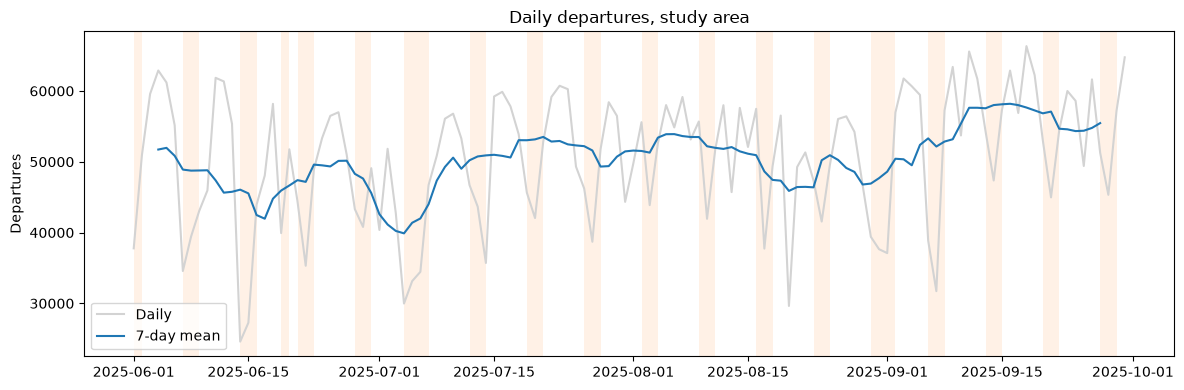

In [9]:
daily = duckdb.sql("""
SELECT date,
       any_value(day_type) AS day_type,
       SUM(departures)     AS departures
FROM panel
GROUP BY date
ORDER BY date
""").df()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily['date'], daily['departures'], color='lightgray', label='Daily')
ax.plot(daily['date'], daily['departures'].rolling(7, center=True).mean(), color='tab:blue', label='7-day mean')
for d in daily.loc[daily['day_type'] != 'weekday', 'date']:
    ax.axvspan(d, d + pd.Timedelta(days=1), color='tab:orange', alpha=0.1, lw=0)
ax.set_title('Daily departures, study area')
ax.set_ylabel('Departures')
ax.legend()
plt.tight_layout()
plt.show()

### Hourly departure profile
Average area departures per hour by day type.

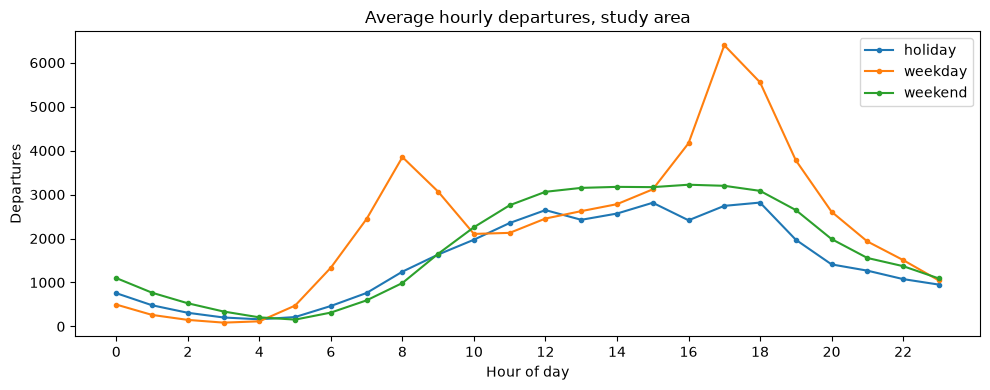

In [10]:
profile = duckdb.sql("""
WITH area AS (
    SELECT date, hr, day_type, SUM(departures) AS departures
    FROM panel
    GROUP BY date, hr, day_type
)
SELECT day_type, hr, AVG(departures) AS avg_departures
FROM area
GROUP BY day_type, hr
ORDER BY day_type, hr
""").df()

fig, ax = plt.subplots(figsize=(10, 4))
for day_type, g in profile.groupby('day_type'):
    ax.plot(g['hr'], g['avg_departures'], marker='o', ms=3, label=day_type)
ax.set_title('Average hourly departures, study area')
ax.set_xlabel('Hour of day')
ax.set_ylabel('Departures')
ax.set_xticks(range(0, 24, 2))
ax.legend()
plt.tight_layout()
plt.show()

**Key findings: demand over time**
- An average weekday has 54,491 departures and an average weekend day 42,376 (−22%).
- Weekdays are bimodal: about 3,850 departures at 8 AM and 6,400 at 5 PM, so the evening peak is 1.7× the morning peak. Weekends and holidays show a single midday plateau of about 3,000 departures per hour from noon to 6 PM.
- The 7-day mean ranges from about 40,000 (the July 4 week) to 58,000 (mid-September). Demand rises in September, so a September test set sits above the training-period level.
- Isolated single-day drops to 25,000–30,000 departures are larger than the weekday/weekend gap, which points to weather.

## 5. Station heterogeneity

### Distribution of hourly departures
Mean, variance and share of zero hours for station-level hourly departures. Variance well above the mean (overdispersion) and many zeros favour a Poisson or Tweedie objective over squared error.

In [11]:
duckdb.sql("""
SELECT ROUND(AVG(departures), 2)                       AS mean,
       ROUND(VAR_SAMP(departures), 2)                  AS variance,
       ROUND(100.0 * AVG((departures = 0)::INT), 1)    AS zero_pct,
       quantile_cont(departures, [0.5, 0.9, 0.99])     AS q50_q90_q99,
       MAX(departures)                                 AS max
FROM panel
""").show()

┌────────┬──────────┬──────────┬───────────────────┬───────┐
│  mean  │ variance │ zero_pct │    q50_q90_q99    │  max  │
│ double │  double  │  double  │     double[]      │ int64 │
├────────┼──────────┼──────────┼───────────────────┼───────┤
│    9.2 │   114.42 │     17.5 │ [6.0, 22.0, 48.0] │   216 │
└────────┴──────────┴──────────┴───────────────────┴───────┘



### Morning vs. evening net flow per station
Average weekday net flow per station for 7–10 AM and 4–7 PM. Residential stations sit in the top-left (lose bikes in the morning, gain them back in the evening); office stations sit in the bottom-right.

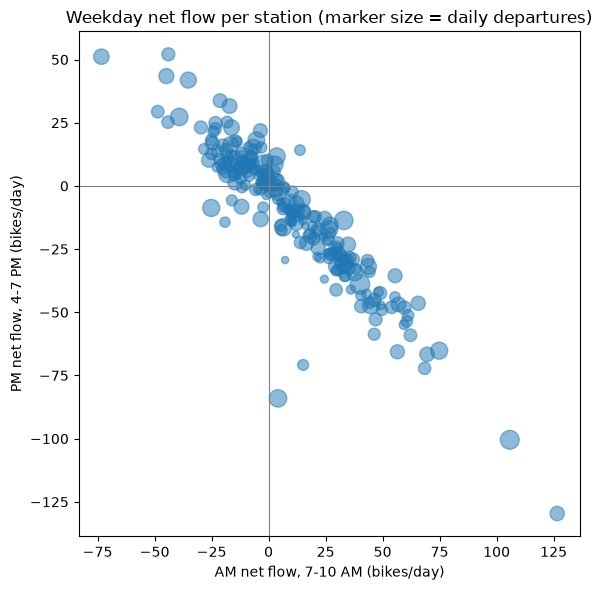

In [12]:
station_flow = duckdb.sql("""
SELECT p.station_id,
       any_value(s.name)                                                     AS name,
       SUM(arrivals - departures) FILTER (WHERE hr BETWEEN 7 AND 9)
           / COUNT(DISTINCT date)                                             AS am_net,
       SUM(arrivals - departures) FILTER (WHERE hr BETWEEN 16 AND 18)
           / COUNT(DISTINCT date)                                             AS pm_net,
       SUM(departures) / COUNT(DISTINCT date)                                AS daily_departures
FROM panel p
JOIN study_stations s USING (station_id)
WHERE day_type = 'weekday'
GROUP BY p.station_id
""").df()

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(station_flow['am_net'], station_flow['pm_net'],
           s=station_flow['daily_departures'] / 3, alpha=0.5)
ax.axhline(0, color='gray', lw=0.8)
ax.axvline(0, color='gray', lw=0.8)
ax.set_title('Weekday net flow per station (marker size = daily departures)')
ax.set_xlabel('AM net flow, 7-10 AM (bikes/day)')
ax.set_ylabel('PM net flow, 4-7 PM (bikes/day)')
plt.tight_layout()
plt.show()

### Largest morning imbalances
The five stations with the largest weekday morning outflow and inflow.

In [13]:
cols = ['name', 'am_net', 'pm_net', 'daily_departures']
print('Largest AM outflow')
print(station_flow.nsmallest(5, 'am_net')[cols].round(1).to_string(index=False))
print('\nLargest AM inflow')
print(station_flow.nlargest(5, 'am_net')[cols].round(1).to_string(index=False))

Largest AM outflow
                         name  am_net  pm_net  daily_departures
             W 43 St & 10 Ave   -73.3    51.1             371.5
             W 44 St & 11 Ave   -48.6    29.4             245.7
Christopher St & Greenwich St   -44.8    43.4             355.1
             E 20 St & FDR Dr   -44.1    25.2             240.6
          FDR Drive & E 35 St   -44.0    52.1             265.6

Largest AM inflow
              name  am_net  pm_net  daily_departures
E 47 St & Park Ave   126.6  -129.6             320.2
   9 Ave & W 33 St   105.8  -100.5             553.3
Broadway & W 25 St    74.8   -65.2             454.2
   E 40 St & 5 Ave    69.5   -66.7             327.3
E 40 St & Park Ave    68.4   -72.2             235.5


**Key findings: station heterogeneity**
- Station-hour departures average 9.2 with a variance of 114.4 (12× the mean); 17.5% of station-hours have zero departures and the 99th percentile is 48. The counts are overdispersed.
- Morning and evening net flows are strongly negatively correlated: most stations reverse their morning imbalance in the evening.
- Residential stations (e.g. W 43 St & 10 Ave, −73 AM / +51 PM bikes per day) cluster on the west side, the West Village and along the FDR Drive. Office stations (e.g. E 47 St & Park Ave, +127 / −130; 9 Ave & W 33 St, +106 / −101) cluster around Grand Central, Midtown East and Penn Station.
- The largest office-station imbalances exceed 100 bikes per day, likely more than the station's dock count, so overnight repositioning alone cannot fully balance them.

## 6. Weather and holidays

### Rain effect
For each day type and hour (7 AM–10 PM), compares average area departures in rainy hours (≥ 0.5 mm) with dry hours (0 mm), then averages the ratio. Comparing within the same hour removes the time-of-day pattern.

In [14]:
duckdb.sql("""
WITH area AS (
    SELECT hour_ts, hr, day_type,
           any_value(precip_mm) AS precip_mm,
           SUM(departures)      AS departures
    FROM panel
    GROUP BY hour_ts, hr, day_type
),
by_cell AS (
    -- rainy vs. dry mean for each day type and hour
    SELECT day_type, hr,
           AVG(departures) FILTER (WHERE precip_mm >= 0.5) AS rain_mean,
           AVG(departures) FILTER (WHERE precip_mm = 0)    AS dry_mean,
           COUNT(*) FILTER (WHERE precip_mm >= 0.5)        AS rainy_hours
    FROM area
    WHERE hr BETWEEN 7 AND 21
      AND day_type <> 'holiday'
    GROUP BY day_type, hr
)
SELECT day_type,
       SUM(rainy_hours) AS rainy_hours,
       ROUND(100 * (AVG(rain_mean / dry_mean) FILTER (WHERE rainy_hours > 0) - 1), 1) AS rain_effect_pct
FROM by_cell
GROUP BY day_type
""").show()

┌──────────┬─────────────┬─────────────────┐
│ day_type │ rainy_hours │ rain_effect_pct │
│ varchar  │   int128    │     double      │
├──────────┼─────────────┼─────────────────┤
│ weekend  │          35 │           -38.5 │
│ weekday  │          65 │           -21.0 │
└──────────┴─────────────┴─────────────────┘



### Temperature effect
Dry hours only. `rel_demand` is departures divided by the average for the same day type and hour, so 1.0 means a typical hour.

In [15]:
duckdb.sql("""
WITH area AS (
    SELECT hour_ts, hr, day_type,
           any_value(temp_c)    AS temp_c,
           any_value(precip_mm) AS precip_mm,
           SUM(departures)      AS departures
    FROM panel
    GROUP BY hour_ts, hr, day_type
),
rel AS (
    SELECT *,
           departures / AVG(departures) OVER (PARTITION BY day_type, hr) AS rel_demand
    FROM area
    WHERE hr BETWEEN 7 AND 21
      AND precip_mm = 0
      AND day_type <> 'holiday'
)
SELECT (floor(temp_c / 3) * 3)::INT AS temp_bin_c,
       COUNT(*)                     AS n_hours,
       ROUND(AVG(rel_demand), 3)    AS rel_demand
FROM rel
GROUP BY temp_bin_c
ORDER BY temp_bin_c
""").show()

┌────────────┬─────────┬────────────┐
│ temp_bin_c │ n_hours │ rel_demand │
│   int32    │  int64  │   double   │
├────────────┼─────────┼────────────┤
│         12 │       7 │      1.004 │
│         15 │      56 │      0.936 │
│         18 │     208 │      0.986 │
│         21 │     304 │      1.016 │
│         24 │     357 │      1.021 │
│         27 │     281 │      1.018 │
│         30 │     158 │      0.981 │
│         33 │      74 │      0.946 │
│         36 │      30 │      0.927 │
│         39 │      10 │      0.806 │
└────────────┴─────────┴────────────┘
  10 rows                 3 columns



### Holidays
Daily departures on each holiday compared with the average weekday and weekend day.

In [16]:
duckdb.sql("""
WITH daily AS (
    SELECT date, day_type, SUM(departures) AS departures
    FROM panel
    GROUP BY date, day_type
)
SELECT date::VARCHAR AS day, day_type, departures
FROM daily
WHERE day_type = 'holiday'
UNION ALL
SELECT 'average', day_type, ROUND(AVG(departures))
FROM daily
WHERE day_type <> 'holiday'
GROUP BY day_type
""").show()

┌────────────┬──────────┬────────────┐
│    day     │ day_type │ departures │
│  varchar   │ varchar  │   double   │
├────────────┼──────────┼────────────┤
│ 2025-09-01 │ holiday  │    37100.0 │
│ 2025-07-04 │ holiday  │    29978.0 │
│ 2025-06-19 │ holiday  │    39924.0 │
│ average    │ weekday  │    54491.0 │
│ average    │ weekend  │    42376.0 │
└────────────┴──────────┴────────────┘



**Key findings: weather and holidays**
- Rain cuts demand by 21% on weekdays and 39% on weekends; weekend trips are more discretionary. Only 100 rainy hours fall in the 7 AM–10 PM window, so these estimates are noisy.
- Temperature has a smaller, non-linear effect: demand is about 2% above normal at 21–29 °C and falls at 33 °C and above (−5% to −19%, few hours in the hottest bins).
- Holidays have 30,000–40,000 departures, at or below an average weekend day (42,376); July 4 is the lowest at 29,978. Their hourly shape matches weekends.

## 7. Implications for forecasting and optimization
- **Target and objective:** forecast hourly departures and arrivals per station with a Poisson or Tweedie objective, because the counts are overdispersed and often zero.
- **Features:** hour of day × day type, holiday flag, station identity and its morning/evening net-flow profile, precipitation, and temperature (non-linear, suited to a tree model).
- **Level shifts:** demand rises in September, so the model needs recent-level features such as lags at 24 hours and 168 hours.
- **Validation:** time-based split, with the final weeks of September held out as the test set.
- **Optimization:** include an external depot that supplies about 1,000 bikes per day, and treat office stations with 100+ bike daily imbalances as cases overnight repositioning can only partly fix.

## 8. Save outputs

### Save `panel`
Writes the hourly station panel, with calendar fields and weather, to Parquet for the forecasting notebook.

In [17]:
duckdb.sql(f"""
COPY (SELECT * FROM panel ORDER BY station_id, hour_ts)
TO '{processed_dir}/panel.parquet' (FORMAT PARQUET)
""")